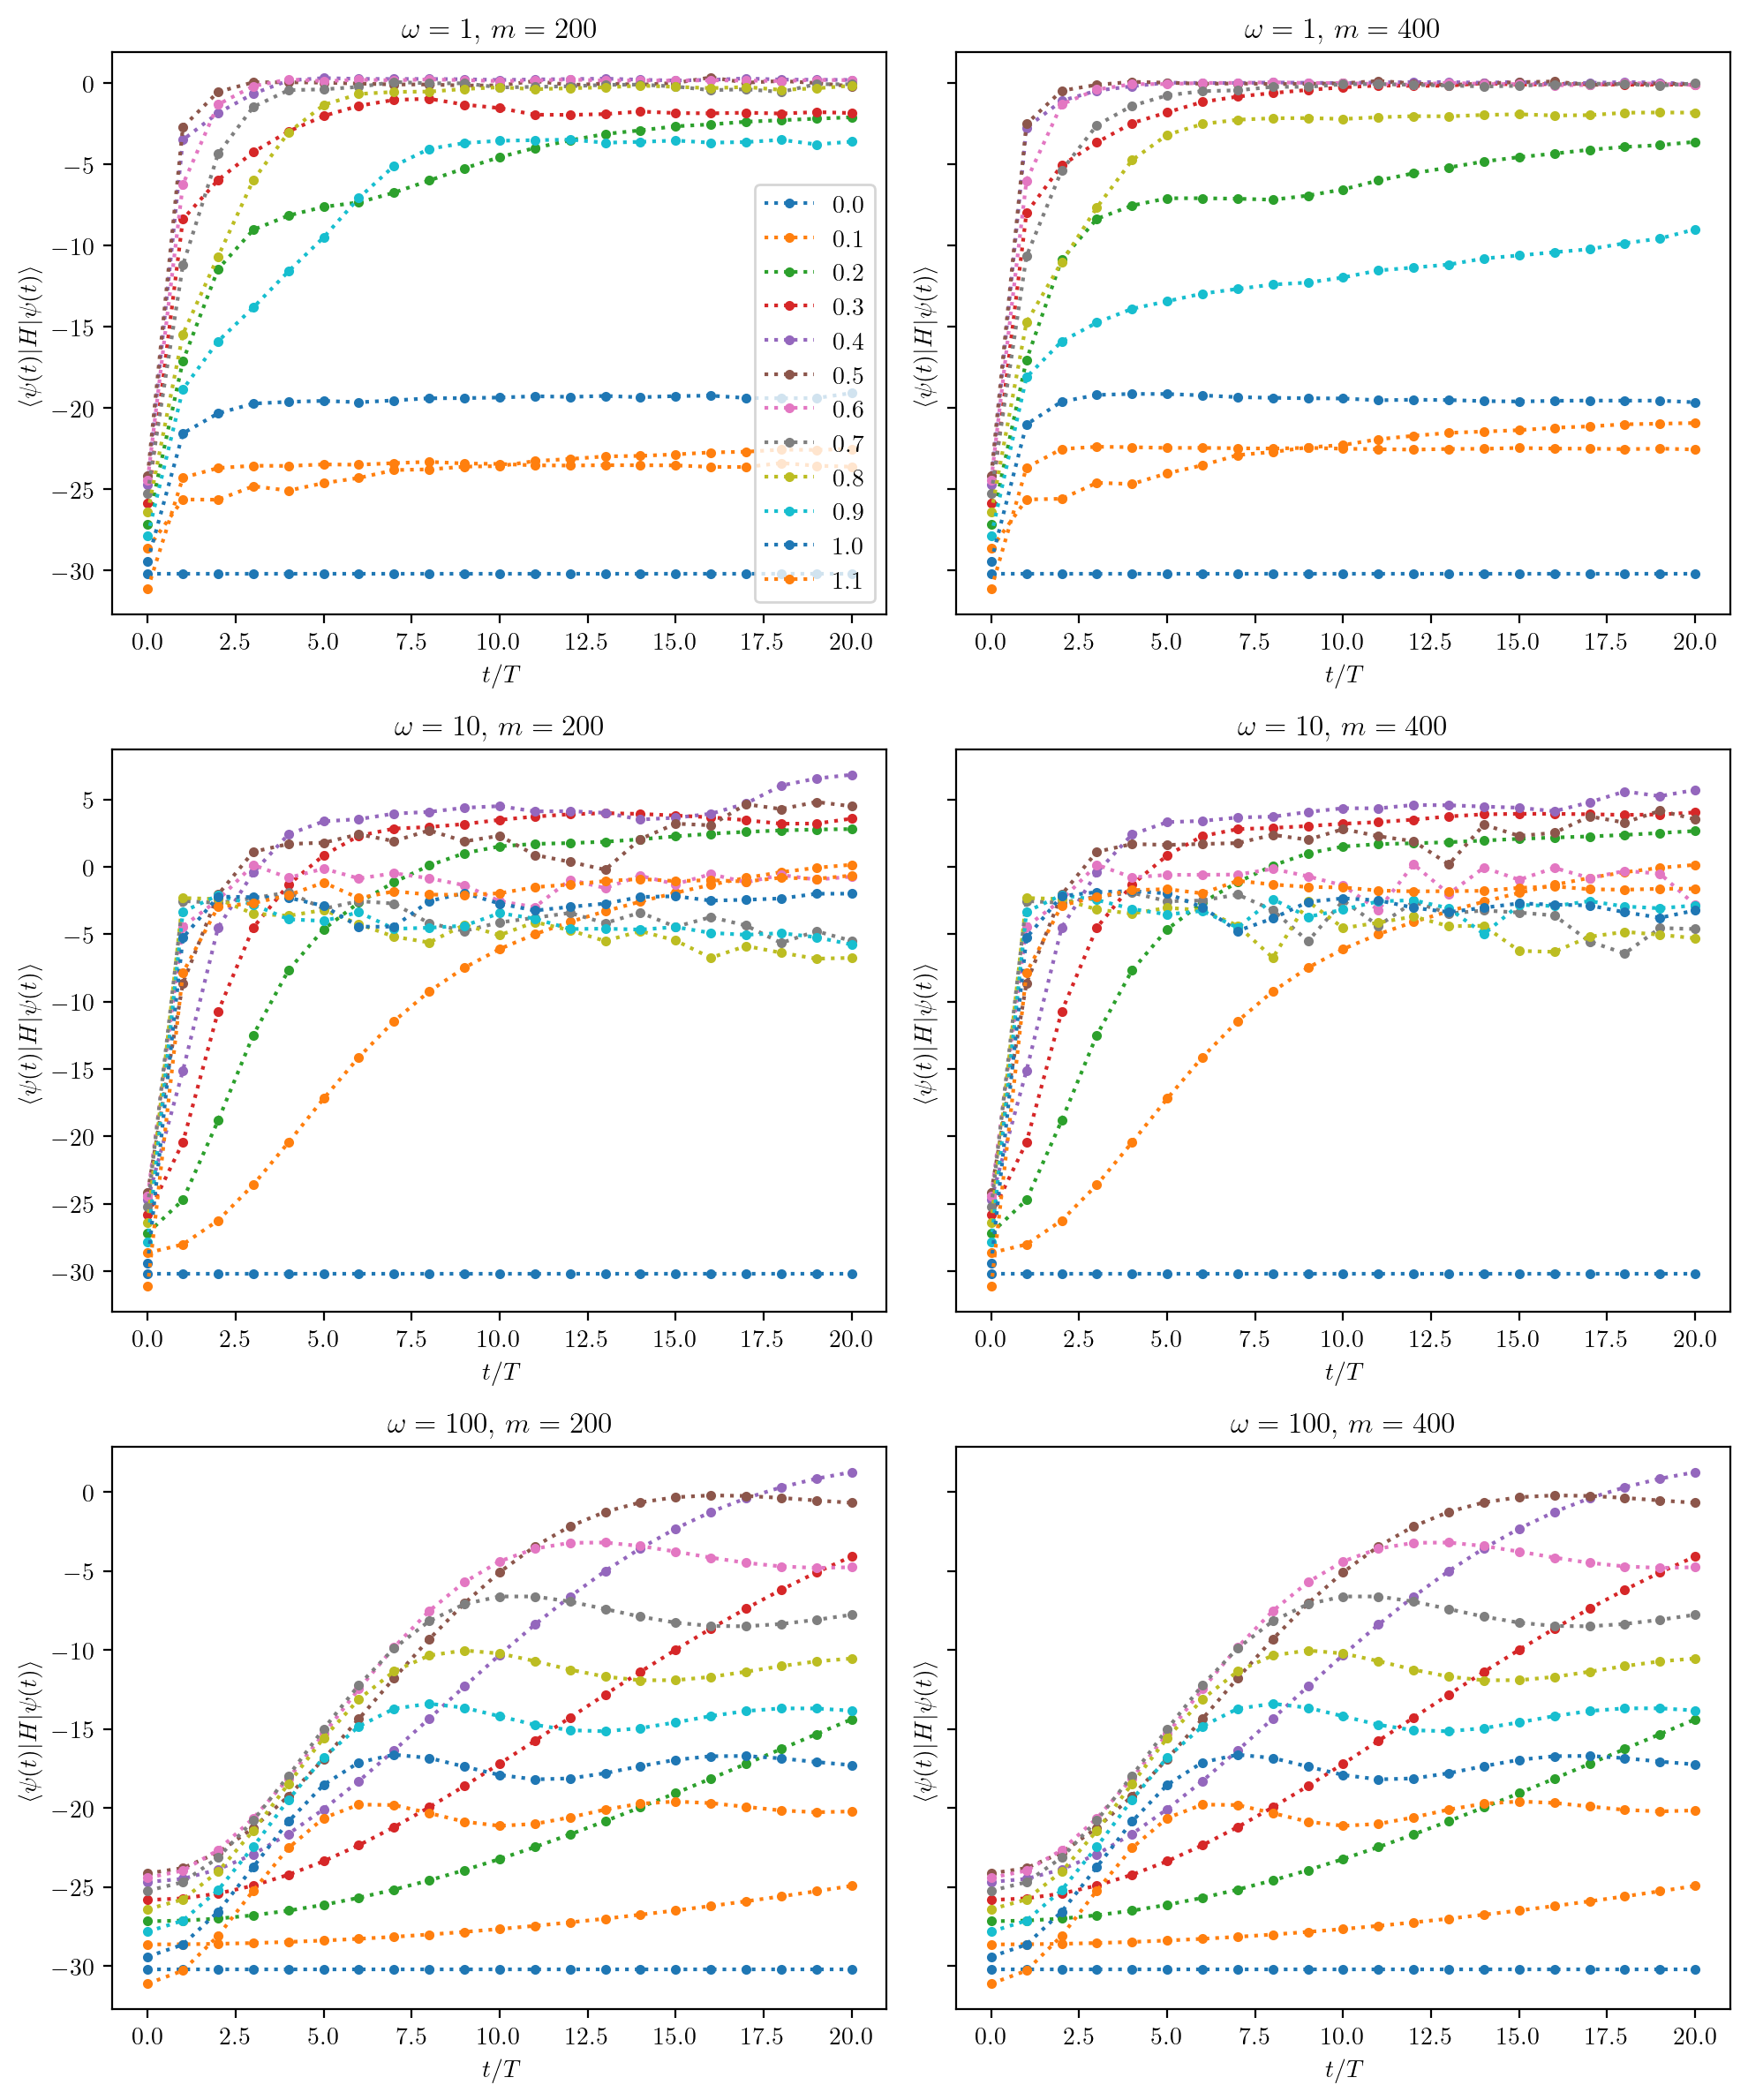

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import h5py

plt.style.use("../majorana.mplstyle")

gs = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1]
omegas = [1.0, 10.0, 100.0]
maxdims = [200, 400]
bc = "OBC"

fig, axes = plt.subplots(len(omegas), len(maxdims), figsize=(10, 12), dpi=200, sharey="row")
for i, omega in enumerate(omegas):
    for j, m in enumerate(maxdims):
        for g in gs:
            with h5py.File(f"tebd_batches_2026-05/L24_{bc}_m{m}/om{omega}_g{g}_site1_peven/output.h5", "r") as f:
                sp = f["steps_per_period"][()]
                t = f["times"][()][::sp] * omega / (2 * np.pi)
                E = f["energy_0"][()][::sp]
            if omega == -1:
                axes[i, j].plot(t[t<2.1], E[t<2.1], ".:", label=g)
            else:
                axes[i, j].plot(t, E, ".:", label=g)
        axes[i, j].set(title=rf"$\omega = {omega:g}$, $m = {m}$", xlabel=r"$t/T$", ylabel=r"$\langle\psi(t)|H|\psi(t)\rangle$")
axes[0, 0].legend()
fig.tight_layout()
plt.savefig(f"period_energies_{bc}.pdf", bbox_inches="tight")

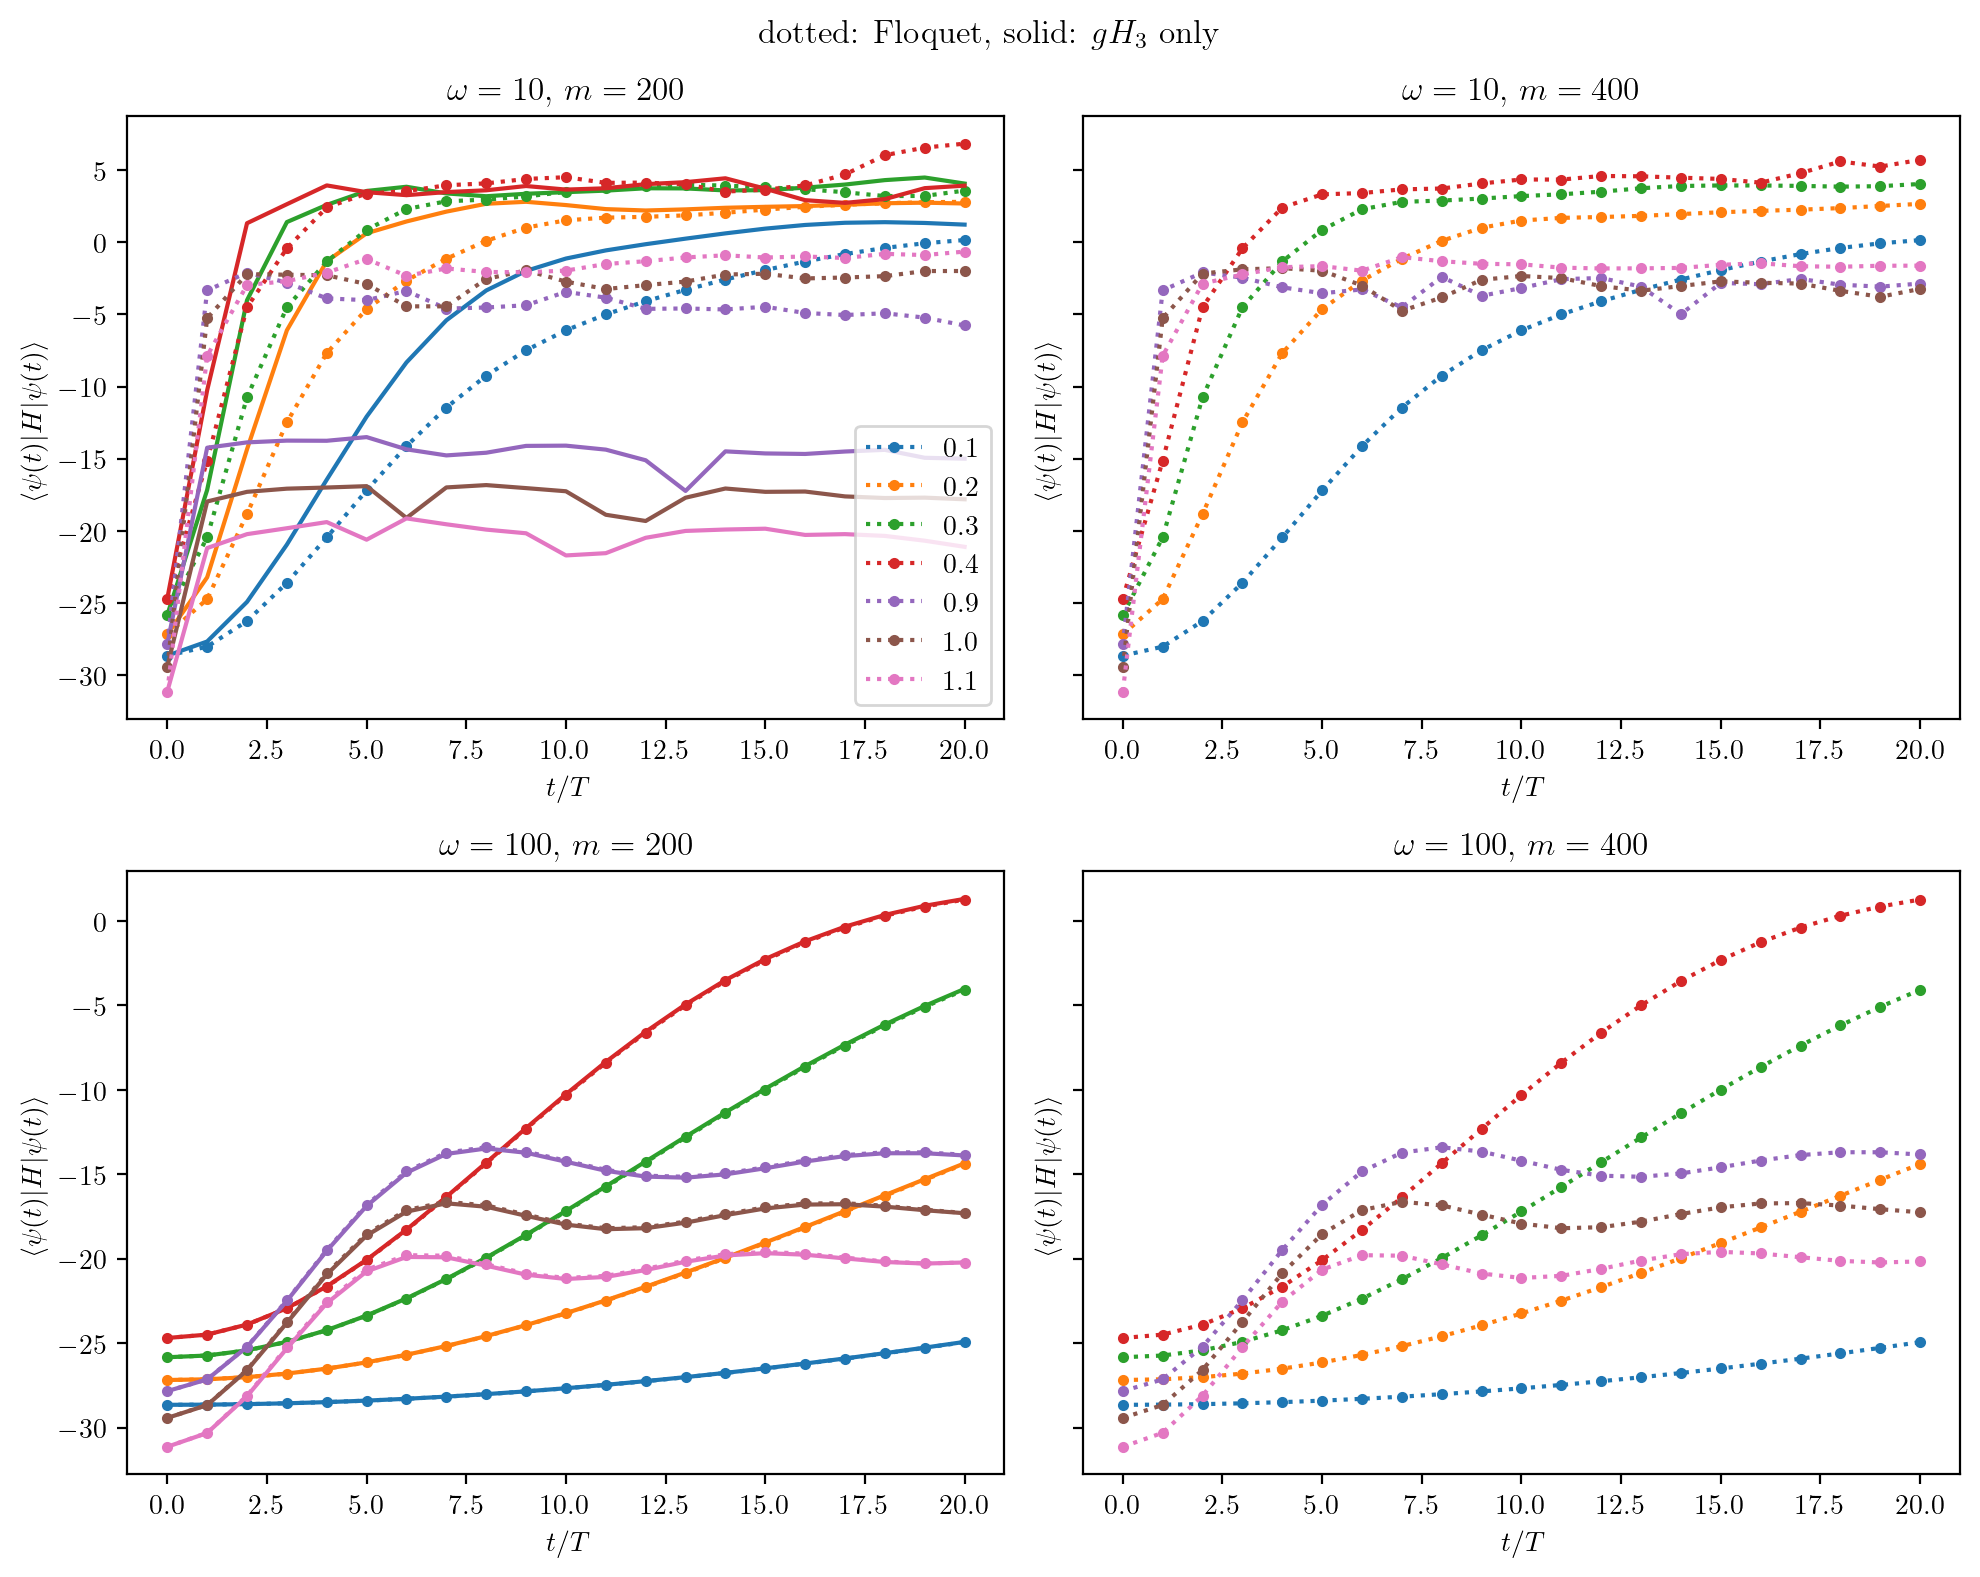

In [15]:
import os

omegas = [10.0, 100.0]
gs = [0.1, 0.2, 0.3, 0.4, 0.9, 1.0, 1.1]
runs = {"tebd_batches_2026-05": ".:", "tebd_h3_batches_2026-11": "-"}

fig, axes = plt.subplots(len(omegas), len(maxdims), figsize=(10, 4 * len(omegas)), dpi=200, sharey="row", squeeze=False)
for i, omega in enumerate(omegas):
    for j, m in enumerate(maxdims):
        for k, g in enumerate(gs):
            for run, style in runs.items():
                fname = f"{run}/L24_{bc}_m{m}/om{omega}_g{g}_site1_peven/output.h5"
                if not os.path.exists(fname):
                    continue
                with h5py.File(fname, "r") as f:
                    sp = f["steps_per_period"][()]
                    t = f["times"][()][::sp] * omega / (2 * np.pi)
                    E = f["energy_0"][()][::sp]
                axes[i, j].plot(t, E, style, color=f"C{k}", label=g if run == "tebd_batches_2026-05" else None)
        axes[i, j].set(title=rf"$\omega = {omega:g}$, $m = {m}$", xlabel=r"$t/T$", ylabel=r"$\langle\psi(t)|H|\psi(t)\rangle$")
axes[0, 0].legend()
fig.suptitle(r"dotted: Floquet, solid: $gH_3$ only")
fig.tight_layout()
plt.savefig(f"h3_energies_{bc}.pdf", bbox_inches="tight")